<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
UE L2 Projet de Statistique CMI OSIA
</div>

</a>
<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Année 2026-2027
</div>
<div style="color: blue; font-size: 1.5em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Nom : BOSSON  Prénom : Raphael

Nom : PACHER  Prénom : Alexis
</div>


Modèle de compte-rendu du projet avec codes commentés, sorties numériques et graphiques



<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Importation des données
</div>

Le code ci-dessous permet d'importer ces différents fichiers, de visualiser leur contenu ainsi que leur organisation sous forme de DataFrame Pandas.

**Noms et coordonnées des stations**

In [1]:
import pandas as pd

stations_toulouse = pd.read_parquet("stations_toulouse.parquet")

**Données d'entrainement**

``history_toulouse_train`` dans le code ci-dessous est un DataFrame Pandas, avec :
- des lignes identifiées par un MultiIndex (nom de la station et date de mesure)
- des colonnes nommées ``bikes`` et ``stands``qui contiennent respectivement le nombre de vélos disponibles et le nombre de vélos manquants pour une station et une date (jour/heure) données

In [2]:
history_toulouse_train = pd.read_parquet("history_toulouse_train.parquet")

**Données de test**

``history_toulouse_test`` dans le code ci-dessous est un DataFrame Pandas, avec :
- des lignes identifiées par un MultiIndex (une station à la date de la dernière mesure faite dans les données d'entraînement)
- des colonnes nommées ``bikes_+15min``,...,``bikes_+120min`` qui doivent être complétées par des prévisions tous les 15 minutes pendant 2 heures

In [3]:
history_toulouse_test = pd.read_parquet("history_toulouse_test.parquet")

<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Statistique descriptive des données
</div>

Vous devez inclure ici les résultats de statistique descriptive qui vous semblent pertinents pour le problème de prévision du nombre de vélos. Vous devez en particulier répondre aux questions suivantes :

- (a) déterminer le nombre maximal de vélos disponibles par station et afficher sur une carte les stations en fonction d'un code couleur proportionnel à ce nombre
- (b) déterminer s'il existe des valeurs manquantes dans les données
- (c) déterminer les nombres de mesures pour chaque station et afficher un histogramme de leur répartition
- (d) déterminer les dates de début et de fin des mesures par stations, et faire une représentation graphique de leur dispersion
- (e) proposer des statistique de base par station : maximimum, minimum, moyenne, écart-type, quartiles, et en faire une représentation par Boxplot
- (f) calculer la courbe moyenne journalière de remplissage d'une station (toutes les 15 minutes), et de l'ensemble des stations / calculer également la courbe médiane, 1er-quartile, 3-ème quartile
- (g) tracer sur quelques cartes l'évolution temporelle de remplissage moyen de l'ensemble des stations en choisissant quelques moments dans une journée et en déduire des dynamiques urbaines de remplissage en fonction des heures de la journée et de la localisation des stations
- (h) autres idées ?...

**A compléter...**

In [4]:
import pandas as pd
import numpy as np
import folium
import branca.colormap as cm
import matplotlib.pyplot as plt
from folium.plugins import TimestampedGeoJson

history_toulouse_test = pd.read_parquet("history_toulouse_test.parquet")
history_toulouse_train = pd.read_parquet("history_toulouse_train.parquet")
stations_toulouse = pd.read_parquet("stations_toulouse.parquet")

</div>
On importe toutes les bibliothèques utiles ainsi que les fichiers.

(a) déterminer le nombre maximal de vélos disponibles par station et afficher sur une carte les stations en fonction d'un code couleur proportionnel à ce nombre


In [5]:
# nb_max_bikes by map

maxi = (
    history_toulouse_train
    .groupby(level="station")
    .max()
    .copy()
)
max_bikes = maxi["bikes"]
stations_toulouse["nombre_max_velos"] = (
    stations_toulouse["station"].map(max_bikes)
)

</div>
Ici, on recupère le nombre maximum de vélo par station. Ensuite, on associe le nombre maximum de vélos à la latitude et longitude de leur station.

In [6]:
# Carte centrée sur les stations
m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs basée sur le nombre maximum de vélos
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_toulouse["nombre_max_velos"].min(),
    vmax=stations_toulouse["nombre_max_velos"].max(),
    caption="Nombre maximum de vélos"
)

# Ajouter les stations
for _, row in stations_toulouse.dropna(
    subset=["nombre_max_velos"]
).iterrows():

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(row["nombre_max_velos"]),
        fill=True,
        fill_color=colormap(row["nombre_max_velos"]),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Nombre maximum de vélos :</b>
            {row['nombre_max_velos']}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{row['nombre_max_velos']} vélos maximum"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

</div>
On a maintenant fait apparaitre la carte avec le nombre maximum de vélos par station. On a ajouter une échelle de couleur afin de mieux visualiser où sont majoritairement concentré les vélos.
Ainsi, on peut voir que plus on se rapproche du centre-ville plus le maximum de vélos est important. On en conclue donc que la majorité des vélos sont utilisés pour au centre-ville.

(b) déterminer s'il existe des valeurs manquantes dans les données

In [7]:
valeurs_manquantes = history_toulouse_train.isna().sum()
valeurs_manquantes

bikes     0
stands    0
dtype: int64

</div>
Il n'y a pas de valeurs manquantes.

(c) déterminer les nombres de mesures pour chaque station et afficher un histogramme de leur répartition

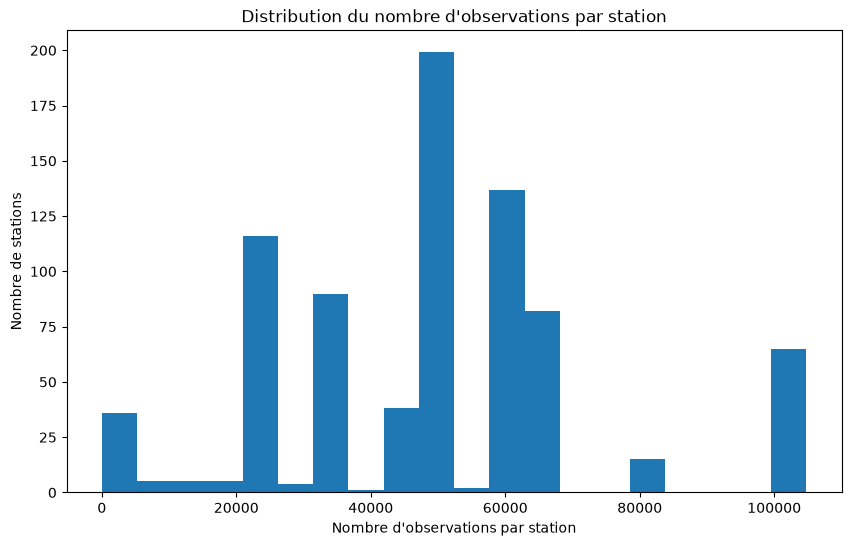

In [8]:
nb_obs = (
    history_toulouse_train
    .groupby(level="station")
    .count()
)
vect_nb_obs = nb_obs["bikes"]

plt.figure(figsize=(10, 6))

plt.hist(vect_nb_obs, bins=20)

plt.xlabel("Nombre d'observations par station")
plt.ylabel("Nombre de stations")
plt.title("Distribution du nombre d'observations par station")

plt.show()

</div>
La majorité des stations ont entre 45 000 et 70 000 mesures.

(d) déterminer les dates de début et de fin des mesures par stations, et faire une représentation graphique de leur dispersion

In [9]:
firstm = (
    history_toulouse_train
    .groupby(level="station")
    .head(1)
    .copy()
)
firstm

,,bikes,stands
station,commit_at,,
00001 - POIDS DE L'HUILE,2023-08-05 12:15:00,10,9
00002 - LAFAYETTE,2023-08-05 12:15:00,24,0
00003 - ALSACE - LORRAINE - POMME,2024-10-31 10:00:00,17,0
00003 - ALSACE-LORRAINE - POMME,2025-11-10 14:30:00,16,1
00003 - POMME,2023-08-05 12:15:00,14,4
...,...,...,...
NARBONNE - CLOTASSES,2025-08-13 14:15:00,0,0
PASTEUR - LAVOISIER,2025-08-04 10:00:00,0,0
PLACE GEORGES BRASSENS,2025-08-05 09:15:00,0,0


</div>
On voit ici que les données n'ont pas du tout été prelevé en même temps.

In [10]:
lastm = (
    history_toulouse_train
    .groupby(level = "station")
    .tail(1)
    .copy()
)
lastm

,,bikes,stands
station,commit_at,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,9,7
00002 - LAFAYETTE,2026-07-31 23:45:00,9,9
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,18,0
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,12,4
00003 - POMME,2025-01-05 05:45:00,17,0
...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,0,16
PASTEUR - LAVOISIER,2025-08-05 10:15:00,0,0
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,0,0


</div>
C'est pareil pour la fin des mesures. On peut avoir jusqu'à un an d'écart entre deux stations. D'autant plus, pour la dernière station on peut voir que l'on a au maximum deux mois de données.

In [11]:
donnees_first = firstm.index.get_level_values("commit_at")
donnees_last = lastm.index.get_level_values("commit_at")
station = firstm.index.get_level_values("station")

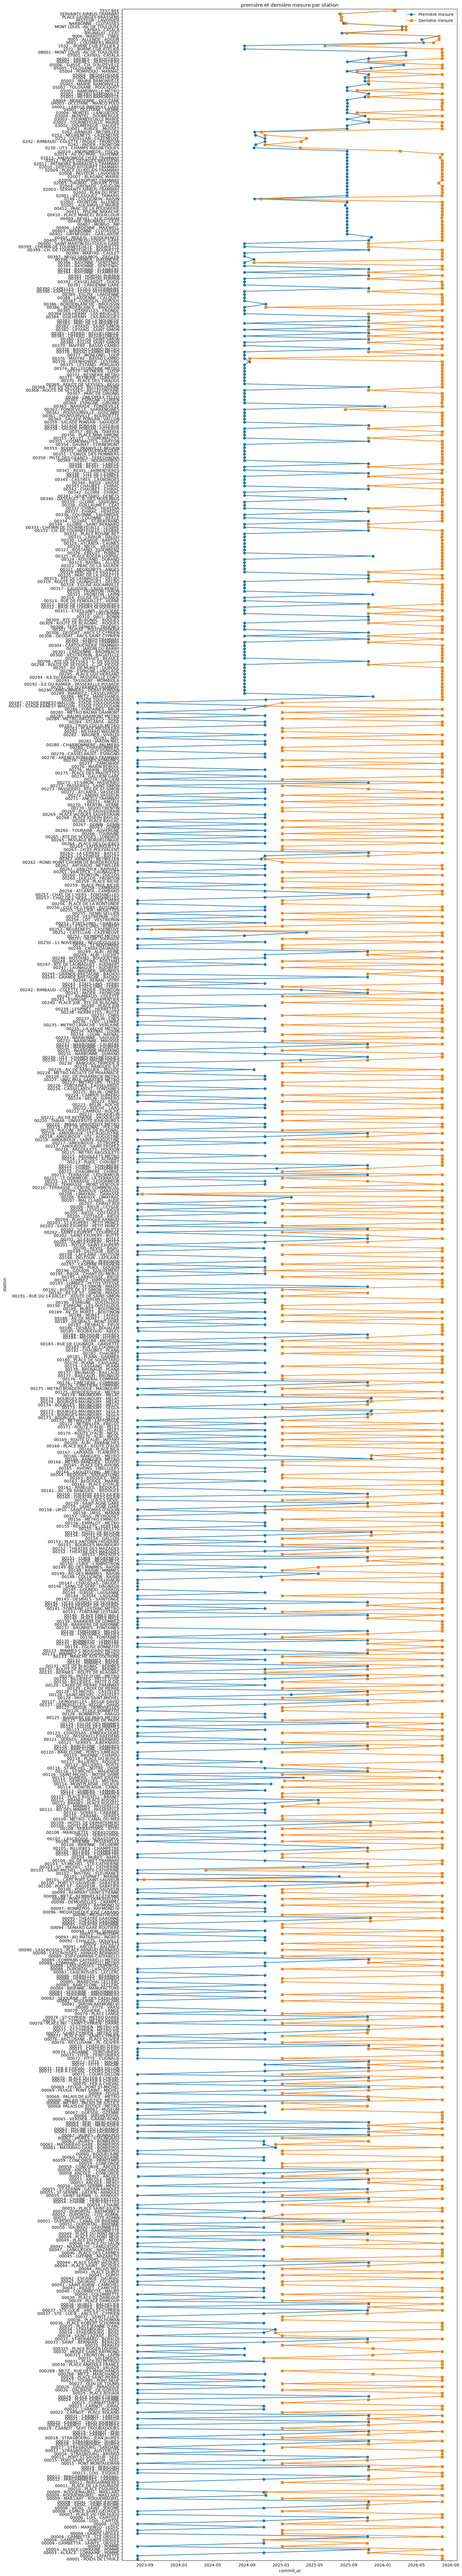

In [12]:
import matplotlib.dates as mdates
from datetime import datetime

plt.figure(figsize=(15, 115))
position = range(len(station))
plt.ylim(position[0] - 0.5,position[-1] + 0.5)
plt.plot(donnees_first, station, marker='o', label='Première mesure')
plt.plot(donnees_last, station, marker='s', label='Dernière mesure')

plt.ylabel('station')
plt.xlabel('commit_at')
plt.title('première et dernière mesure par station')
plt.legend()
plt.show()

</div> 
On constate donc que la majorité des temps d'observations est assez longue (espace entre les points bleu et orange)  sauf pour certaines station comme les 5 dernières.

(e) proposer des statistique de base par station : maximimum, minimum, moyenne, écart-type, quartiles, et en faire une représentation par Boxplot

In [13]:
station = "00001 - POIDS DE L'HUILE"
donnees_station = history_toulouse_train.loc[station]
bikes_station = donnees_station["bikes"]
print("Résultat première station")
print("minimum des vélos :",bikes_station.min())
print("maximum des vélos :",bikes_station.max())
print("median des vélos :" ,bikes_station.median())
print("somme total des vélos :",bikes_station.sum())
print("nombre de vélos :",bikes_station.count())
print("moyenne des vélos :",bikes_station.mean())

Résultat première station
minimum des vélos : 0
maximum des vélos : 20
median des vélos : 3.0
somme total des vélos : 612978
nombre de vélos : 104775
moyenne des vélos : 5.85042233357194


In [45]:
stations = history_toulouse_train.index.get_level_values("station").unique()[:10]
donnees = history_toulouse_train.loc[history_toulouse_train.index.get_level_values("station").isin(stations)]

moy = (
    donnees
    .groupby(level=0)["bikes"]
        .mean()
)

mini = (
    donnees
    .groupby(level=0)["bikes"]
        .min()
)

maxi = (
    donnees
    .groupby(level=0)["bikes"]
        .max()
)

medi = (
    donnees
    .groupby(level=0)["bikes"]
        .median()
)
quart = (
    donnees
    .groupby(level=0)["bikes"]
        .quantile(0.25)
)
tquart = (
    donnees
    .groupby(level=0)["bikes"]
        .quantile(0.75)
)
ecart = (
    donnees
    .groupby(level=0)["bikes"]
        .std()
    .copy()
)
moy, mini, maxi, medi, quart, tquart, ecart

(station
 00001 - POIDS DE L'HUILE               5.850422
 00002 - LAFAYETTE                      9.863566
 00003 - ALSACE - LORRAINE - POMME      4.317652
 00003 - ALSACE-LORRAINE - POMME        5.815927
 00003 - POMME                         10.052652
 00004 - GAMBETTA - SAINTE - URSULE     4.861967
 00004 - GAMBETTA - SAINTE-URSULE       9.200000
 00004 - GAMBETTA - STE-URSULE          6.340913
 00004 - SAINTE-URSULE                  6.938091
 00005 - LEDUC                          4.882006
 Name: bikes, dtype: float64,
 station
 00001 - POIDS DE L'HUILE              0
 00002 - LAFAYETTE                     0
 00003 - ALSACE - LORRAINE - POMME     0
 00003 - ALSACE-LORRAINE - POMME       0
 00003 - POMME                         0
 00004 - GAMBETTA - SAINTE - URSULE    0
 00004 - GAMBETTA - SAINTE-URSULE      7
 00004 - GAMBETTA - STE-URSULE         0
 00004 - SAINTE-URSULE                 0
 00005 - LEDUC                         0
 Name: bikes, dtype: uint8,
 station
 00001 - POIDS 

</div>
On a calculé la moyenne du nombres de vélos pour les dix premières stations.  Toutes les stations ont un minimum de 0 sauf une qui en a un de 7. on trouve également deux valeurs isolées pour le maximum. En effet, une station a un maximum de 25 tandis qu'une autre en a un de 10, alors qu'en générale, ils sont au alentours de 20. Enfin, on constate 2 pic pour les médianes.

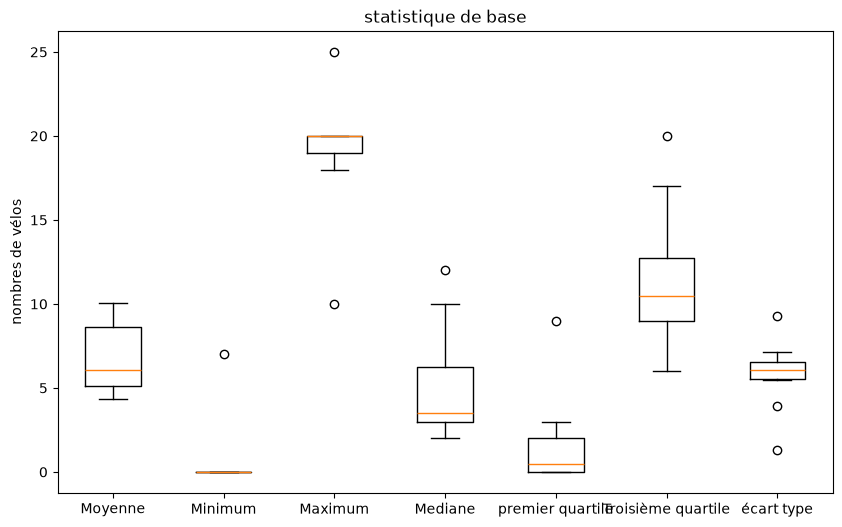

In [58]:
plt.figure(figsize=(10, 6))
plt.boxplot([moy, mini, maxi, medi, quart, tquart, ecart], tick_labels = ['Moyenne','Minimum','Maximum','Mediane','premier quartile','Troisième quartile','écart type'])
plt.title("statistique de base")
plt.ylabel("nombres de vélos")
plt.show()

</div>
On représente les valeurs récupéré précédemment. Ainsi, on peut voir que les moyennes des dix premières stations sont n'ont pas d'écart trop important.Avec la représentation du boxplot, on voit clairement qu'il y a en moyenne 0 vélo au minimum sauf pour une. Avec la représentation du boxplot, on voit clairement qu'il y a en moyenne une vingtaine de vélos au minimum sauf pour pour deux qui en ont respectivement 10 et 25. Avec le boxplot, on peut ainsi voir que la moyenne de la médiane des stations est plutôt basse et que deux station ont plutôt une médiane haute. Il y a une station avec un premier quartile très important. Les autres stations sont en moyenne à 1 ou 2. En moyenne, les stations ont leur troisième quartile 11 ou 12. La moyenne des écart-types est à 6, sauf pour trois stations.

In [53]:
nb_v = (
    donnees
    .groupby(level=0)["bikes"]
        .count()
)
sumv = (
    donnees
    .groupby(level=0)["bikes"]
        .sum()
)
nb_v, sumv

(station
 00001 - POIDS DE L'HUILE              104775
 00002 - LAFAYETTE                     104783
 00003 - ALSACE - LORRAINE - POMME      36008
 00003 - ALSACE-LORRAINE - POMME        25278
 00003 - POMME                          49799
 00004 - GAMBETTA - SAINTE - URSULE     35593
 00004 - GAMBETTA - SAINTE-URSULE           5
 00004 - GAMBETTA - STE-URSULE          25684
 00004 - SAINTE-URSULE                  49799
 00005 - LEDUC                          49799
 Name: bikes, dtype: int64,
 station
 00001 - POIDS DE L'HUILE               612978
 00002 - LAFAYETTE                     1033534
 00003 - ALSACE - LORRAINE - POMME      155470
 00003 - ALSACE-LORRAINE - POMME        147015
 00003 - POMME                          500612
 00004 - GAMBETTA - SAINTE - URSULE     173052
 00004 - GAMBETTA - SAINTE-URSULE           46
 00004 - GAMBETTA - STE-URSULE          162860
 00004 - SAINTE-URSULE                  345510
 00005 - LEDUC                          243119
 Name: bikes, dtype: uin

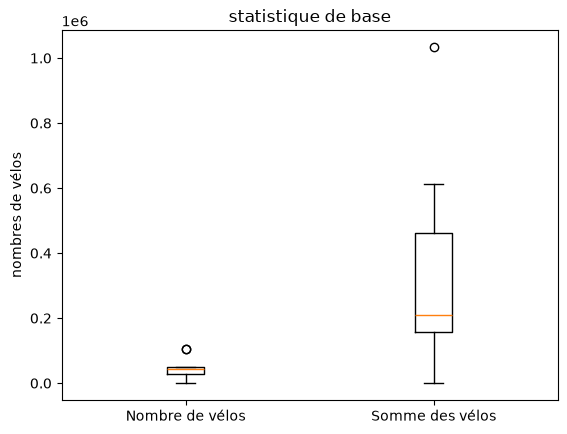

In [57]:
plt.boxplot([nb_v, sumv], tick_labels = ['Nombre de vélos','Somme des vélos'])
plt.title("statistique de base")
plt.ylabel("nombres de vélos")
plt.show()

</div>
Ici, le box plot est à l'echelle donc le nombre de vélos est en million. Avec le boxplot, on peut ainsi voir que la moyenne du nombre de vélos par stations est plutôt basse et qu'une station a plutôt un nombre de vélos important.

(f) calculer la courbe moyenne journalière de remplissage d'une station (toutes les 15 minutes), et de l'ensemble des stations / calculer également la courbe médiane, 1er-quartile, 3-ème quartile

In [32]:
station1 = "00001 - POIDS DE L'HUILE"
donnees1 = history_toulouse_train.loc[station1]
dates = donnees1.index.get_level_values("commit_at")
donnees1["heure_minute"] = dates.strftime("%H:%M")

moyqh = (
    donnees1
    .groupby(["heure_minute"])[["bikes"]]
        .mean()

)
moyqh

,bikes
heure_minute,
00:00,2.396884
00:15,2.318057
00:30,2.211732
00:45,2.153987
01:00,2.055912
...,...
22:45,3.341888
23:00,3.129239
23:15,2.868928


On calcule la moyenne journalière pour la première station. Ainsi, on peut voir la réppartition des vélos au cours de la journée.

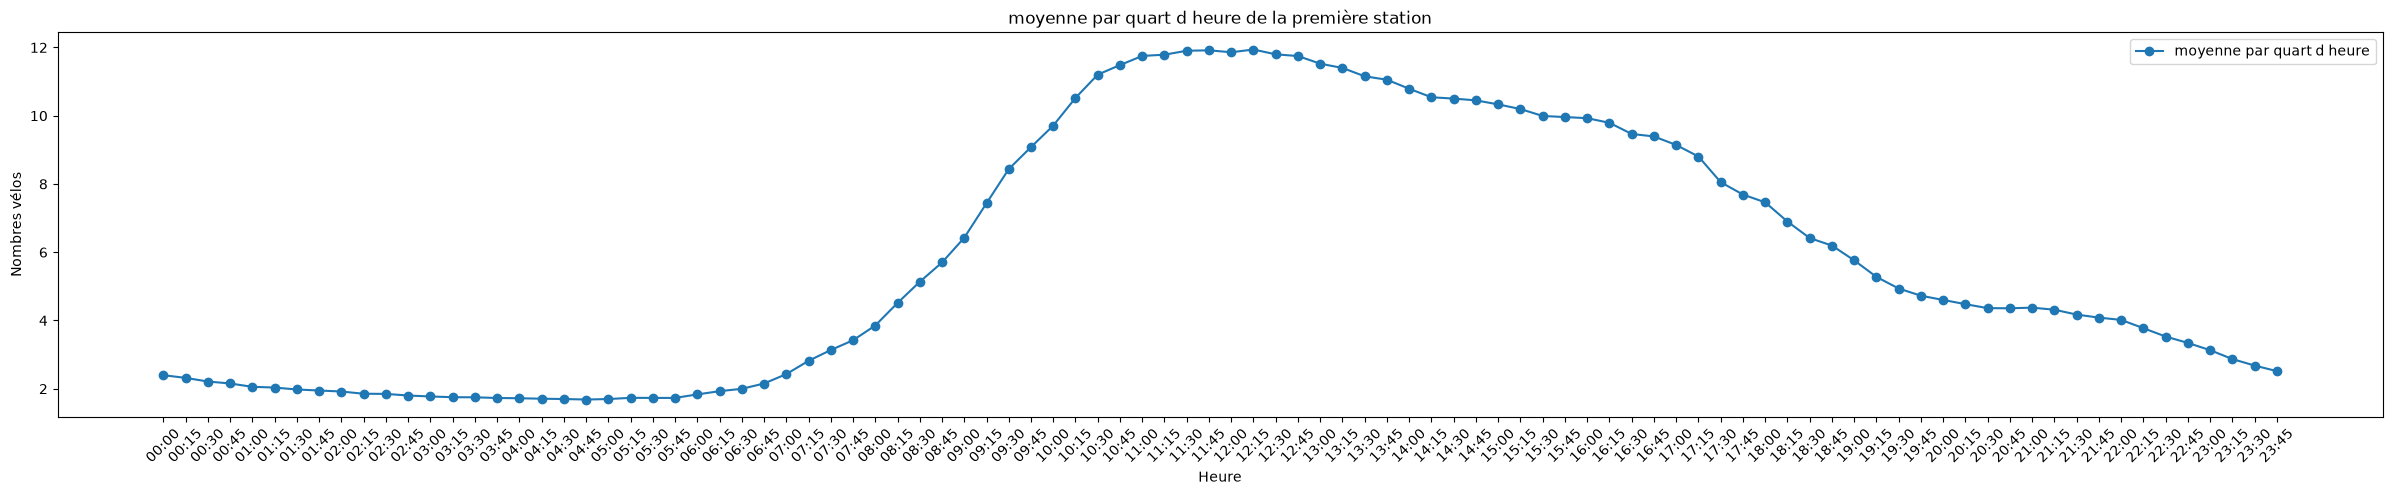

In [33]:
hmin = moyqh.index.get_level_values("heure_minute")
plt.figure(figsize=(30, 5))

plt.plot(hmin, moyqh, marker='o', label='moyenne par quart d heure')
plt.ylabel('Nombres vélos')
plt.xlabel('Heure')
plt.title('moyenne par quart d heure de la première station')
plt.xticks(rotation=45)
plt.legend()

La représentation graphique permet une meilleur visualisation. Si on associe ce graphique avec les coordonnées géographiques, on comprend mieux la fluctuation des vélos au sein de Toulouse durant la journée. En effet, cette station se situe en centre ville, ce qui explique que les vélos arrivent entre 8h et 10h et repartent dans la soirée (ce qui correspond au rythme de travail).

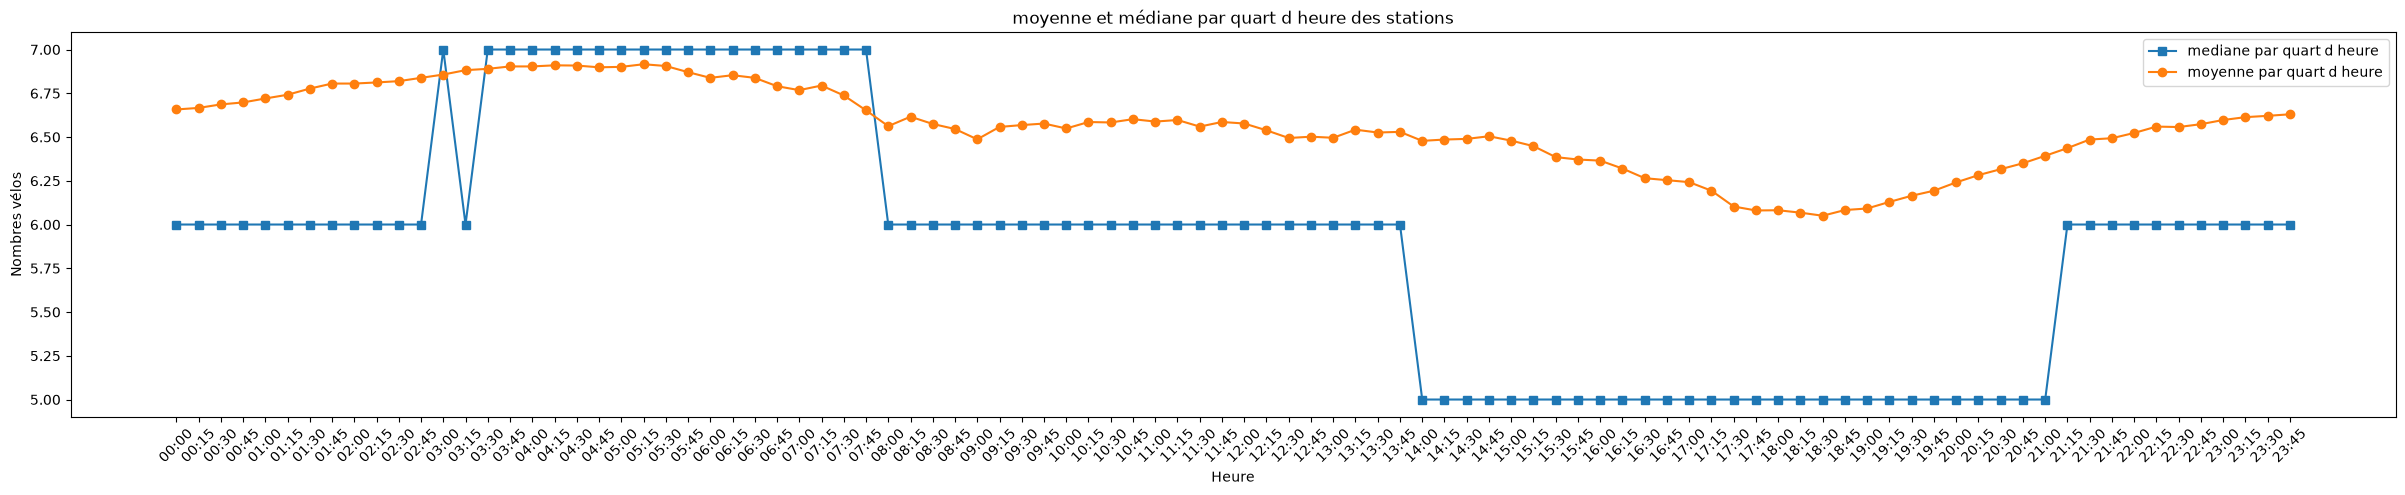

In [59]:
df = history_toulouse_train.copy()
dates = df.index.get_level_values("commit_at")
df["heure_minute"] = dates.strftime("%H:%M")

moy_velos_quart_heure = (
    df
    .groupby(["station", "heure_minute"])[["bikes"]]
    .mean()
    .round()
)
profil_moyen = (
    moy_velos_quart_heure
    .groupby(level="heure_minute")["bikes"]
    .mean()
)
med_velos_quart_heure = (
    df
    .groupby(["station", "heure_minute"])[["bikes"]]
    .median()
    .round()
)
profil_median = (
    med_velos_quart_heure
    .groupby(level="heure_minute")["bikes"]
    .median()
)

plt.figure(figsize=(30, 5))

plt.plot(hmin, profil_median, marker='s', label='mediane par quart d heure')
plt.plot(hmin, profil_moyen, marker='o', label='moyenne par quart d heure')
plt.ylabel('Nombres vélos')
plt.xlabel('Heure')
plt.title('moyenne et médiane par quart d heure des stations')
plt.xticks(rotation=45)
plt.legend()

Dans ce graphique, ce qui est intéréssant ici c'est les creux car c'est le moment ou il y a le plus de vélos en circulation. On retrouve donc bel et bien un creux à 8h et le principal est à 18h. Encore une fois la médiane reflete, l'utilisation des vélos selon le rythme de travail. Cependant, beaucoup de vélos sont rangés durant la nuit jusqu'au petit matin. Ainsi, on peut en déduire que certaines personnes probablement payées range les vélos égaré en ville.

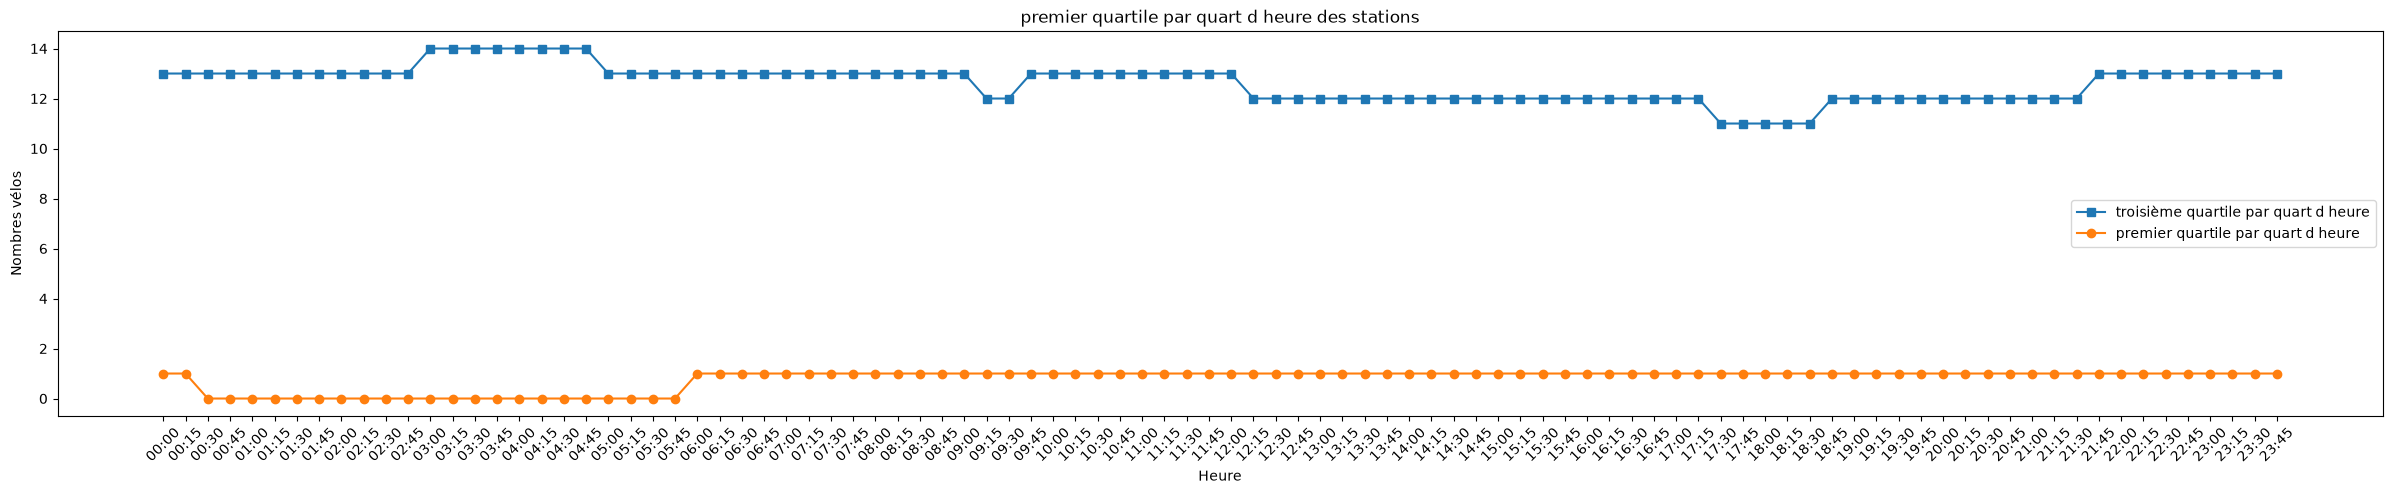

In [60]:
df = history_toulouse_train.copy()
dates = df.index.get_level_values("commit_at")
df["heure_minute"] = dates.strftime("%H:%M")

quart1_velos_quart_heure = (
    df
    .groupby(["station", "heure_minute"])[["bikes"]]
    .quantile(0.25)
    .round()
)
profil_quart1 = (
    quart1_velos_quart_heure
    .groupby(level="heure_minute")["bikes"]
    .quantile(0.25)
)
quart3_velos_quart_heure = (
    df
    .groupby(["station", "heure_minute"])[["bikes"]]
    .quantile(0.75)
    .round()
)
profil_quart3 = (
    quart3_velos_quart_heure
    .groupby(level="heure_minute")["bikes"]
    .quantile(0.75)
)

plt.figure(figsize=(30, 5))

plt.plot(hmin, profil_quart3, marker='s', label='troisième quartile par quart d heure')
plt.plot(hmin, profil_quart1, marker='o', label='premier quartile par quart d heure')
plt.ylabel('Nombres vélos')
plt.xlabel('Heure')
plt.title('premier quartile par quart d heure des stations')
plt.xticks(rotation=45)
plt.legend()

Ce graphique renforce fortement l'hypothèse précédente et illustre à merveille le rangement des vélos durant la nuit ainsi que les horaires de travail.

(g) tracer sur quelques cartes l'évolution temporelle de remplissage moyen de l'ensemble des stations en choisissant quelques moments dans une journée et en déduire des dynamiques urbaines de remplissage en fonction des heures de la journée et de la localisation des stations

In [ ]:
moy_bikes = (
    moy_velos_quart_heure
    .xs("05:00", level="heure_minute")["bikes"]
)

stations_toulouse["nombre_moyen_velos"] = (
    stations_toulouse["station"].map(moy_bikes)
)

m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs basée sur le nombre maximum de vélos
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_toulouse["nombre_moyen_velos"].min(),
    vmax=stations_toulouse["nombre_moyen_velos"].max(),
    caption="Nombre moyen de vélos"
)

# Ajouter les stations
for _, row in stations_toulouse.dropna(
    subset=["nombre_moyen_velos"]
).iterrows():

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(row["nombre_moyen_velos"]),
        fill=True,
        fill_color=colormap(row["nombre_moyen_velos"]),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Nombre moyen de vélos :</b>
            {row['nombre_moyen_velos']}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{row['nombre_moyen_velos']} vélos moyen"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

On peut voir qu'au centre le nombre de vélos est presque nul ainsi qu'à l'extrémité de la ville à 5h du matin.

In [ ]:
moy_bikes = (
    moy_velos_quart_heure
    .xs("12:00", level="heure_minute")["bikes"]
)

stations_toulouse["nombre_moyen_velos"] = (
    stations_toulouse["station"].map(moy_bikes)
)

m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs basée sur le nombre maximum de vélos
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_toulouse["nombre_moyen_velos"].min(),
    vmax=stations_toulouse["nombre_moyen_velos"].max(),
    caption="Nombre moyen de vélos"
)

# Ajouter les stations
for _, row in stations_toulouse.dropna(
    subset=["nombre_moyen_velos"]
).iterrows():

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(row["nombre_moyen_velos"]),
        fill=True,
        fill_color=colormap(row["nombre_moyen_velos"]),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Nombre moyen de vélos :</b>
            {row['nombre_moyen_velos']}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{row['nombre_moyen_velos']} vélos moyen"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

à midi, les vélos qui étaient dans la couronne intérieur sont maintenant au centre.

In [ ]:
moy_bikes = (
    moy_velos_quart_heure
    .xs("22:00", level="heure_minute")["bikes"]
)

stations_toulouse["nombre_moyen_velos"] = (
    stations_toulouse["station"].map(moy_bikes)
)

m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs basée sur le nombre maximum de vélos
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_toulouse["nombre_moyen_velos"].min(),
    vmax=stations_toulouse["nombre_moyen_velos"].max(),
    caption="Nombre moyen de vélos"
)

# Ajouter les stations
for _, row in stations_toulouse.dropna(
    subset=["nombre_moyen_velos"]
).iterrows():

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(row["nombre_moyen_velos"]),
        fill=True,
        fill_color=colormap(row["nombre_moyen_velos"]),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Nombre moyen de vélos :</b>
            {row['nombre_moyen_velos']}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{row['nombre_moyen_velos']} vélos moyen"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

à 22h, les vélos qui étaient au centre sont de nouveau dans la petite couronne car les gens sont rentrés chez eux.

In [ ]:
med_bikes = (
    med_velos_quart_heure
    .xs("05:00", level="heure_minute")["bikes"]
)

stations_toulouse["nombre_median_velos"] = (
    stations_toulouse["station"].map(med_bikes)
)

m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs basée sur le nombre maximum de vélos
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_toulouse["nombre_median_velos"].min(),
    vmax=stations_toulouse["nombre_median_velos"].max(),
    caption="Nombre median de vélos"
)

# Ajouter les stations
for _, row in stations_toulouse.dropna(
    subset=["nombre_median_velos"]
).iterrows():

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(row["nombre_median_velos"]),
        fill=True,
        fill_color=colormap(row["nombre_median_velos"]),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Nombre median de vélos :</b>
            {row['nombre_median_velos']}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{row['nombre_median_velos']} vélos median"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

La médiane marque beaucoup mieux ces fluctuations. Cette carte représente une journée moyenne à 5h du matin.

In [ ]:
quart1_bikes = (
    quart1_velos_quart_heure
    .xs("05:00", level="heure_minute")["bikes"]
)

stations_toulouse["nombre_quart1_velos"] = (
    stations_toulouse["station"].map(quart1_bikes)
)

m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs basée sur le nombre maximum de vélos
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_toulouse["nombre_quart1_velos"].min(),
    vmax=stations_toulouse["nombre_quart1_velos"].max(),
    caption="Nombre quart1 de vélos"
)

# Ajouter les stations
for _, row in stations_toulouse.dropna(
    subset=["nombre_quart1_velos"]
).iterrows():

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(row["nombre_quart1_velos"]),
        fill=True,
        fill_color=colormap(row["nombre_quart1_velos"]),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Nombre quart1 de vélos :</b>
            {row['nombre_quart1_velos']}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{row['nombre_quart1_velos']} vélos quart1"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

Ici on a testé d'autres statisque pour voir si on aurait d'autres informations mais nous n'avons rien trouvé d'autres ce que précédemment trouvé.

In [ ]:
quart3_bikes = (
    quart3_velos_quart_heure
    .xs("05:00", level="heure_minute")["bikes"]
)

stations_toulouse["nombre_quart3_velos"] = (
    stations_toulouse["station"].map(quart3_bikes)
)

m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs basée sur le nombre maximum de vélos
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_toulouse["nombre_quart3_velos"].min(),
    vmax=stations_toulouse["nombre_quart3_velos"].max(),
    caption="Nombre quart3 de vélos"
)

# Ajouter les stations
for _, row in stations_toulouse.dropna(
    subset=["nombre_quart3_velos"]
).iterrows():

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(row["nombre_quart3_velos"]),
        fill=True,
        fill_color=colormap(row["nombre_quart3_velos"]),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Nombre de vélos du troisième:</b>
            {row['nombre_quart3_velos']}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{row['nombre_quart3_velos']} vélos troisième quartile"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

Idem ici.

<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Méthodes de prévision basiques
</div>

Vous devez inclure ici une description des méthodes de bases que vous avez explorées, ainsi qu'une évaluation de leurs performances (cacul de l'erreur RMSE) sur un jeu de données de validation créé à partir de l'ensemble d'apprentissage.

Il est attendu :

- une proposition de 3 méthodes de prévision
- leur classement en terme de performances par calcul de l'erreur RMSE sur l'ensemble de validation
- leurs prévisions sur l'ensemble test à déposer sur Moodle

**Création d'un ensemble de validation**

Le principe de création d'un ensemble de validation est le suivant. Les données disponibles sont partagées en deux sous-ensembles disjoints :

- un ensemble d'apprentissage qui va servir à créer un modèle de prévision
- un ensemble de validation qui va servir à évaluer le modèle de prévision

Il s'agit d'un principe fondamental en apprentissage statistique qui consiste à construire une méthode d'estimation puis **la tester sur un jeu de données qui n'a pas servi à sa construction**.

Dans ce projet, pour créer l'ensemble de validation, on peut simplement retirer les 8 denières mesures dans chaque station de ``history_toulouse_train`` et conserver le reste des données pour l'apprentissage.

In [ ]:
# Exemple de création d'un jeu de données d'apprentissage et un jeu de données de validation

# Création ensemble d'apprentissage
# Suppression des 8 dernières mesures de chaque station
rang_depuis_la_fin = (
    history_toulouse_train
    .groupby(level="station")
    .cumcount(ascending=False)
)
rang_depuis_la_fin

In [ ]:
history_toulouse_apprentissage = history_toulouse_train[
    rang_depuis_la_fin >= 8
].copy()
history_toulouse_apprentissage

In [ ]:
# Récupèration de la dernière date de mesure pour chaque station
# des données d'apprentissage
last_apprentissage = (
    history_toulouse_apprentissage
    .groupby(level="station")
    .tail(1)
    .copy()
)

last_apprentissage

In [ ]:
# Creation de l'ensemble de validation
# On récupère les 9 dernières mesures :
# - la 1ère = dernière mesure dans l'ensemble d'apprentissage
# - les 8 suivantes = valeurs à prédire
last_9 = (
    history_toulouse_train
    .groupby(level="station")
    .tail(9)
    .copy()
)
last_9

In [ ]:
# On remet l'index sous forme de colonnes
last_9 = last_9.reset_index()
last_9

In [ ]:
# Numéro de position parmi les 9 dernières mesures
last_9
    

In [ ]:
last_9["horizon"] = (
    last_9.groupby("station").cumcount()
)
last_9

In [ ]:
# Recherche de valeurs manquantes
missing = last_9.loc[
    last_9[['bikes', 'stands']].isna().any(axis=1),TEST BEE 	2026-02-12 15:00:00 	0 	3
7185 	
    ['station', 'commit_at', 'bikes', 'stands']
]

print(missing)

In [ ]:
# On crée une ligne par station et on récupère les 8 valeurs futures
history_toulouse_validation = (
    last_9
    .pivot(
        index="station",
        columns="horizon",
        values="bikes"
    )
    .drop(columns=0)
    .rename(columns={
        1: "bikes_+15min",
        2: "bikes_+30min",
        3: "bikes_+45min",
        4: "bikes_+60min",
        5: "bikes_+75min",
        6: "bikes_+90min",
        7: "bikes_+105min",
        8: "bikes_+120min"
    })
)

# Récupérer la date de la dernière mesure de l'ensemble d'apprentissage par station
cutoff_times = (
    last_9[last_9["horizon"] == 0]
    .set_index("station")["commit_at"]
)

# Ajouter commit_at
history_toulouse_validation["commit_at"] = cutoff_times

# Mettre station + commit_at en MultiIndex
history_toulouse_validation = (
    history_toulouse_validation
    .reset_index()
    .set_index(["station", "commit_at"])
    .sort_index()
)

history_toulouse_validation

**Exemple d'évaluation d'une méthode de prévision**

On donne ci-dessous l'exemple du calcul de l'erreur RMSE sur l'ensemble de validation d'une méthode de base à partir de la moyenne des vélos par station sur l'ensemble d'apprentissage

In [ ]:
# Creation des données à prédire
history_toulouse_basique = history_toulouse_validation.copy()

# Methode de base
mean_bikes_station = (
    history_toulouse_apprentissage
    .groupby(level="station")["bikes"]
    .mean()
    .round()
)

target_columns = [
    "bikes_+15min",
    "bikes_+30min",
    "bikes_+45min",
    "bikes_+60min",
    "bikes_+75min",
    "bikes_+90min",
    "bikes_+105min",
    "bikes_+120min"
]

# Station correspondant à chaque ligne de l'ensemble de validation
stations_a_predire = history_toulouse_basique.index.get_level_values("station")

# Moyenne de chaque station à prédire
predictions = mean_bikes_station.reindex(stations_a_predire)

# Remplissage des 8 horizons avec la même moyenne
history_toulouse_basique.loc[:, target_columns] = (
    predictions.to_numpy()[:, None]
)

In [ ]:
history_toulouse_basique

In [ ]:
history_toulouse_validation

In [ ]:
# Recherche de valeurs manquantes
print("Nombre de valeurs manquantes :", predictions.isna().sum())
print("Valeurs manquantes :", predictions[predictions.isna()])

In [ ]:
# Gestion des valeurs manquantes
stations_problematiques = stations_a_predire[predictions.isna()]
print(stations_problematiques)

In [ ]:
# Nombre d'observations par station
nb_obs = (
    history_toulouse_train
    .groupby(level="station")
    .count()
)
nb_obs

In [ ]:
import numpy as np
np.min(nb_obs)

In [ ]:
print(nb_obs.loc[stations_problematiques])

In [ ]:
vect_nb_obs = nb_obs["bikes"]

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(vect_nb_obs, bins=20)

plt.xlabel("Nombre d'observations par station")
plt.ylabel("Nombre de stations")
plt.title("Distribution du nombre d'observations par station")

plt.show()

In [ ]:
# Stations sans valeurs manquantes
stations_sans_NaN = stations_a_predire[predictions.notna()]
print(stations_sans_NaN)

In [ ]:
import numpy as np

history_toulouse_validation.values

In [ ]:
# Calcul de l'erreur RMSE sur l'ensemble de validation
rmse = np.sqrt((
    (history_toulouse_basique.values - history_toulouse_validation.values)**2
).mean())
print(f'RMSE',rmse)

In [ ]:
# Calcul de l'erreur RMSE sur l'ensemble de validation
rmse = np.sqrt((
    (history_toulouse_basique.loc[stations_sans_NaN].values- history_toulouse_validation.loc[stations_sans_NaN].values)**2
).mean())
print(f'RMSE',rmse)

<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Prévision par apprentissage statistique
</div>

A venir...